## MTL Trajet: 18 Complete Daily Trip Chains (Flag 18)

### Dataset Overview
Complete daily trip chains linked by chain_id and leg_index, with activities, modes, multi-hour work stays, destination dispersion, and timestamped trajectory points.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Identify characteristic patterns and differences among complete daily trip chains.

Role: Urban mobility-pattern analyst


Category: Complete daily trip chains linked by chain_id and leg_index, with activities, modes, multi-hour work stays, destination dispersion, and timestamped trajectory points.

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do work-centered chains and discretionary-stop chains differ in leg and stop counts?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

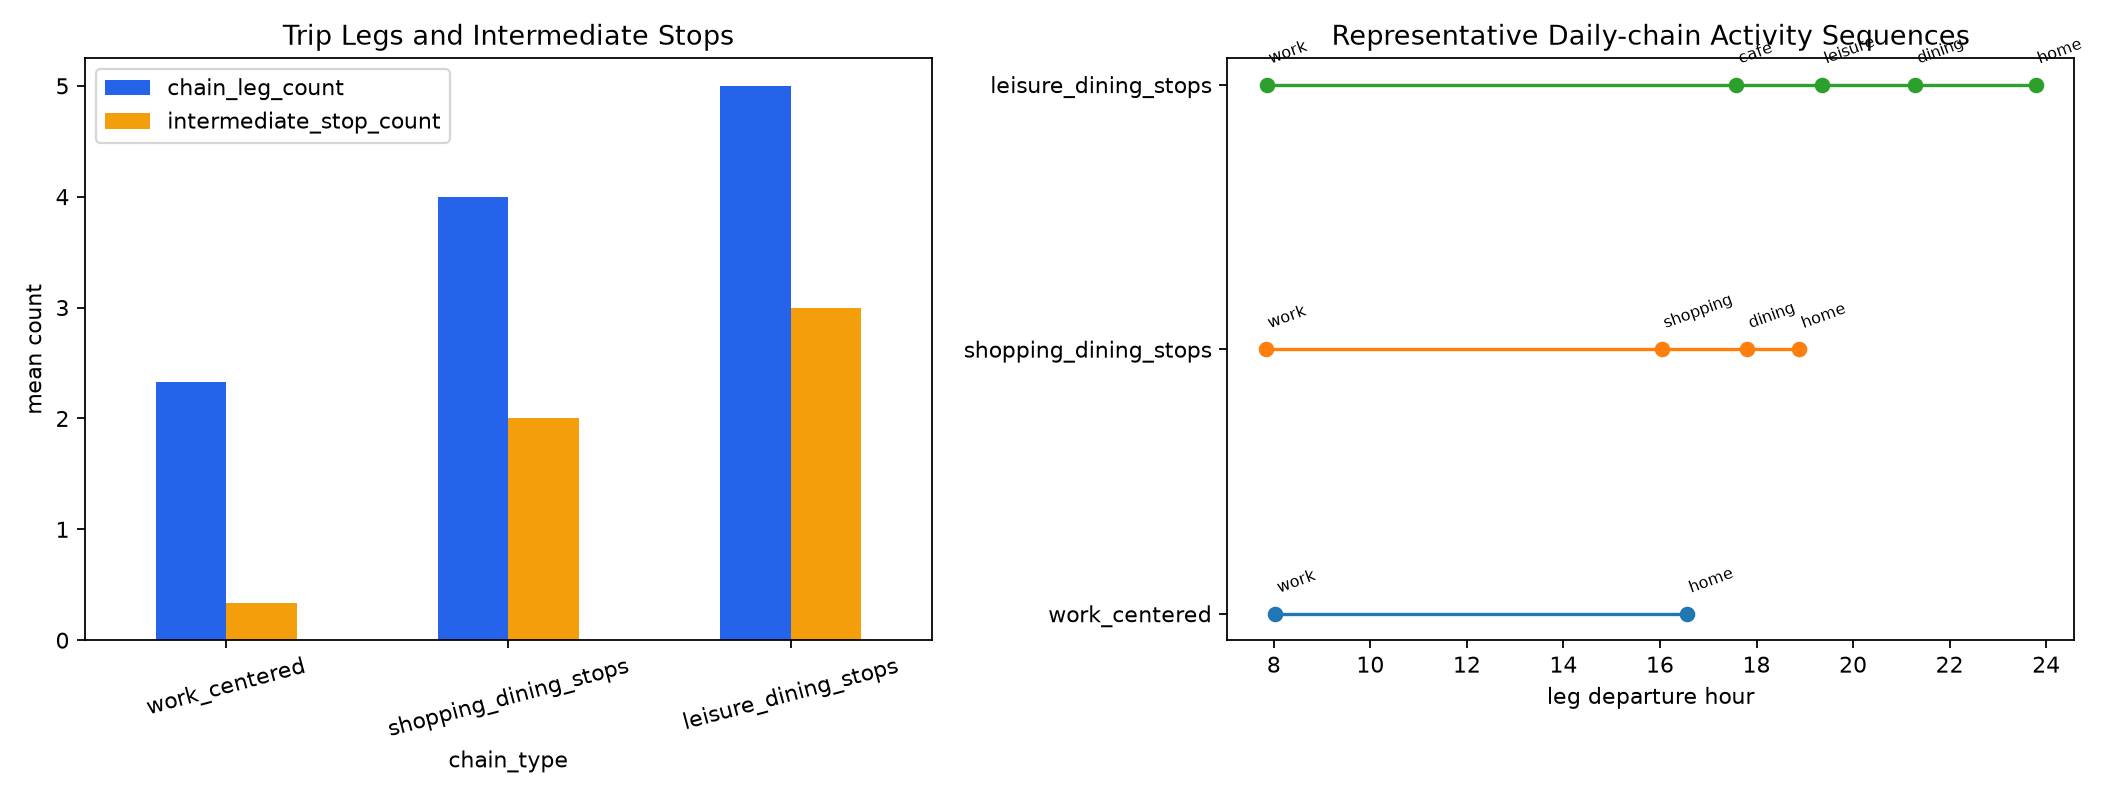

In [ ]:
df.groupby(['chain_id','chain_type']).first().groupby('chain_type')[['chain_leg_count','intermediate_stop_count']].mean()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/daily_chain_structure.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "daily_chain_structure",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Complete Daily-chain Structure",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/daily_chain_structure.png"
  },
  "question": "How do work-centered chains and discretionary-stop chains differ in leg and stop counts?",
  "code": "df.groupby(['chain_id','chain_type']).first().groupby('chain_type')[['chain_leg_count','intermediate_stop_count']].mean()",
  "insight": "Work-centered chains usually contain a direct outbound commute and a return-home leg, while discretionary chains include more intermediate stops.",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "user_id",
    "trip_purpose"
  ]
}

### **Question 2**: How do destination dispersion and mode changes differ when shopping or dining stops are present?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

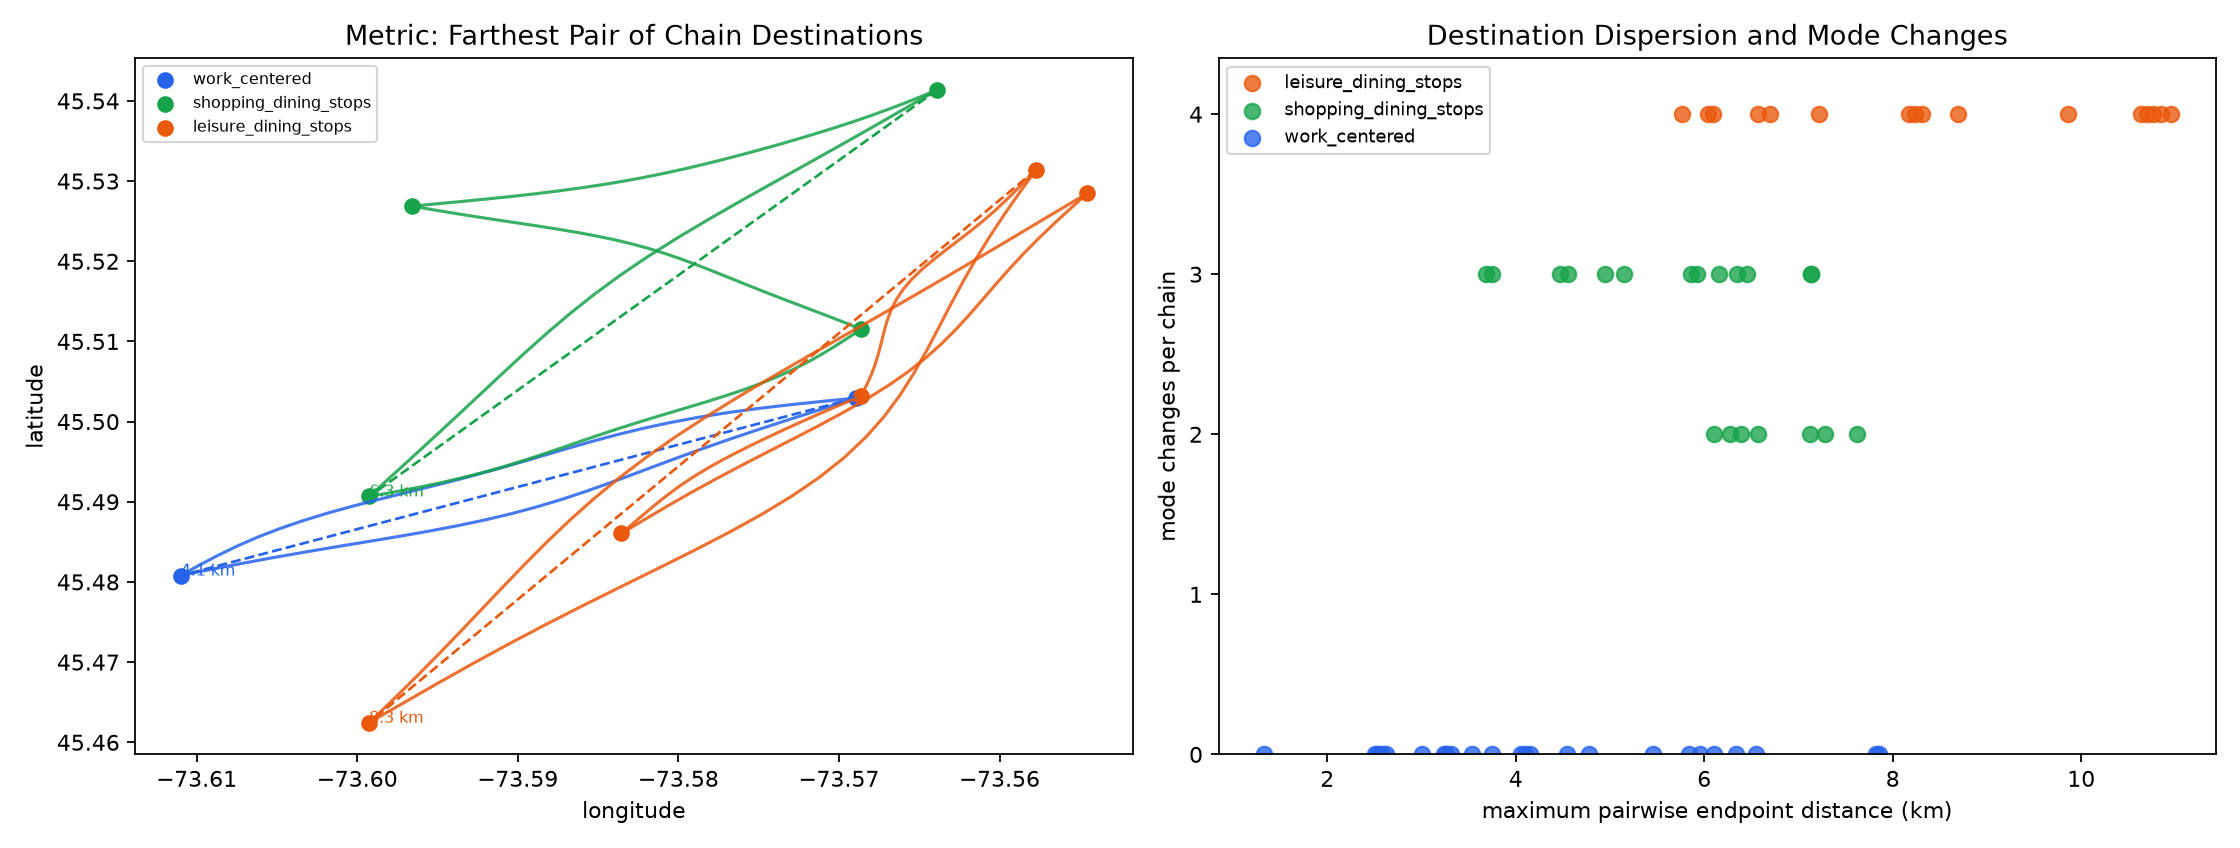

In [ ]:
df.groupby('chain_id').first().groupby('chain_type')[['destination_dispersion_km','mode_change_count']].agg(['median','mean'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/chain_dispersion_and_mode_changes.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "chain_dispersion_mode_change",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Destination Dispersion and Mode Changes",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/chain_dispersion_and_mode_changes.png"
  },
  "question": "How do destination dispersion and mode changes differ when shopping or dining stops are present?",
  "code": "df.groupby('chain_id').first().groupby('chain_type')[['destination_dispersion_km','mode_change_count']].agg(['median','mean'])",
  "insight": "Chains with shopping or dining stops show greater destination dispersion and more frequent mode changes than work-centered chains.",
  "insight_type": "group_comparison",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "trajectory_id",
    "user_id",
    "transport_mode",
    "gps_position"
  ]
}

### **Question 3**: How are leisure or dining stops associated with return-home timing?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

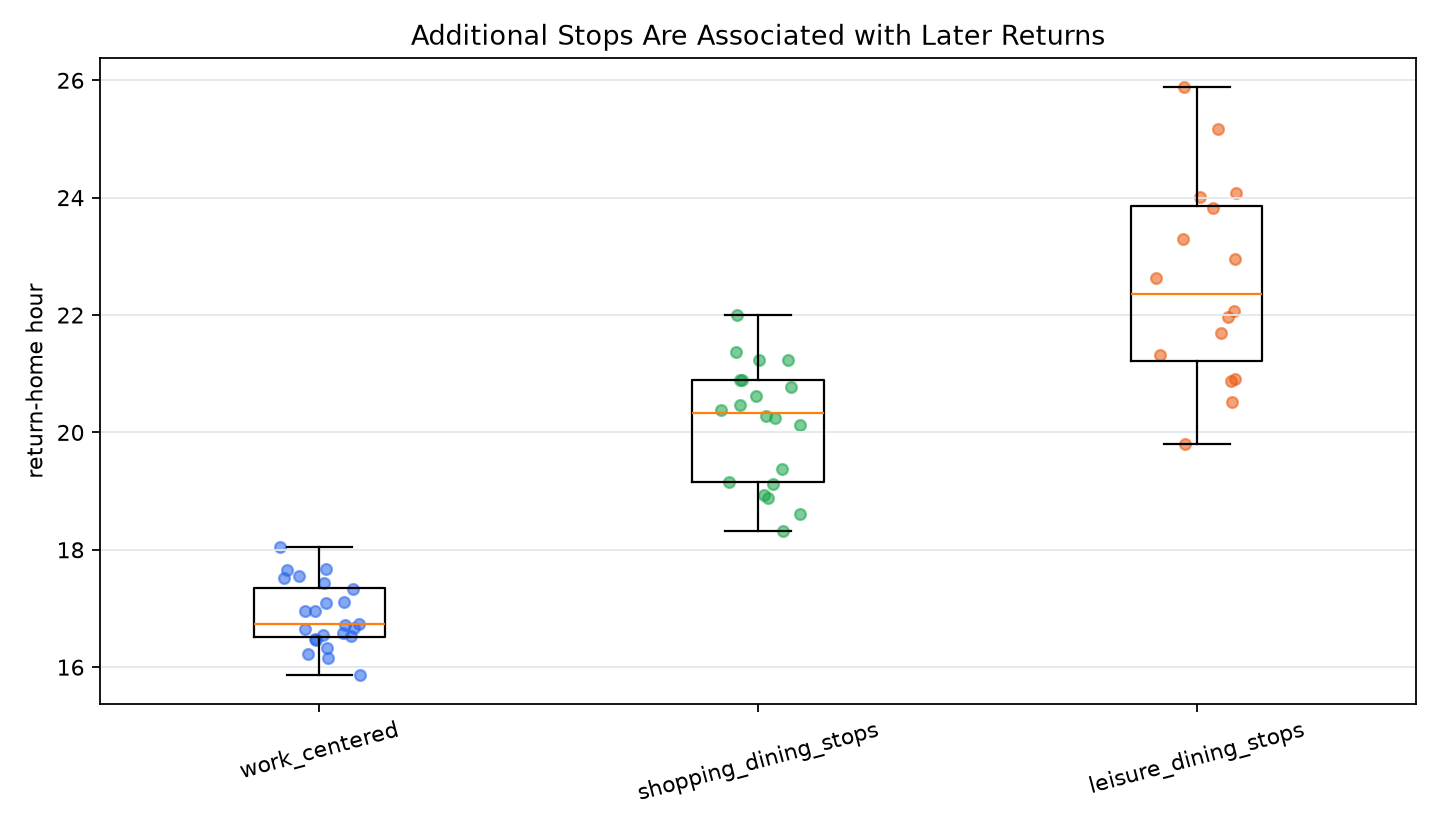

In [ ]:
df.groupby('chain_id').first().groupby('chain_type').return_home_hour.agg(['median','mean','std'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/return_time_by_chain_type.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "chain_return_time",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Return-home Time by Chain Type",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/return_time_by_chain_type.png"
  },
  "question": "How are leisure or dining stops associated with return-home timing?",
  "code": "df.groupby('chain_id').first().groupby('chain_type').return_home_hour.agg(['median','mean','std'])",
  "insight": "Later return-home times are associated with chains containing additional leisure or dining stops, whereas work-centered chains return earlier and more regularly.",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "trajectory_id",
    "user_id"
  ]
}

### Summary of Findings (Flag 18)

Work-centered chains usually contain an outbound commute, a multi-hour work stay, and a return-home leg, while some include a short post-work errand. Chains with shopping, dining, or leisure contain more stops, cover a wider activity space, change modes more often, and return home later.